# 02. Splits and baselines (Consistency)

**Goal.** Lock the train / validation / test roles, prove they leak nothing, and measure the simple baselines every model must beat.
Baselines are scored on **validation** predictions only; the outer test groups are not scored until notebook 08.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="consistency", title="Consistency", folder=Path(".").resolve(), dataset_file="consistency_dataset.csv", label="rater_consistency", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')]
VARIANTS = {'proposal 4': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')], 'proposal 4 + no-activity flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_no_activity', 'raw')], 'proposal 4 + bimodal flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_bimodal', 'raw')], 'proposal 4 + first active day': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_first_active_day', 'raw')], '3 features (no CV)': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus')], 'AWR + 1-DC': [('C_AWR', 'raw'), ('C_DC', 'one_minus')], 'AWR only': [('C_AWR', 'raw')], 'commits (log) + AWR': [('E_CC', 'log'), ('C_AWR', 'raw')]}
FEATURES = ['C_AWR', 'C_DC', 'C_LI_norm', 'C_CV_norm']
ZERO_RULE_OK = True
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Consistency (744, 25)


## 1. The split design

Five student-disjoint groups; each is the **test** group once, and for each test group each of the other four is **validation** once and
the remaining three **train** (20 combinations). Synthetic records are training-only, and only when **both** parents are in training groups.

In [2]:
splits = make_splits(d)
splits.to_csv(F.splits, index=False)
role = splits.join(d[["source", "label_source", "group"]], on="record_id")
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
print(f"wrote {F.splits.name}: {len(splits)} rows, {len(combos)} combinations")
print(environment(F))

wrote splits.csv: 14880 rows, 20 combinations
{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': 'a46a109a5a5c', 'splits_hash': 'b5793a57b501'}


## 2. Leakage checks (all must pass)

In [3]:
problems = []
for (test, val), s in role.groupby(["outer_test", "inner_val"]):
    r = s[s.source == "real"]
    train_g, val_g, test_g = set(r[r.role == "train"].group), set(r[r.role == "val"].group), set(r[r.role == "test"].group)
    if val_g != {val} or test_g != {test} or (train_g & (val_g | test_g)) or (val_g & test_g):
        problems.append((test, val, "group roles"))
    st = r.join(d[["student_id"]], on="record_id").groupby("role").student_id.agg(set)
    if any(st.get(a, set()) & st.get(b, set()) for a, b in (("train", "val"), ("train", "test"), ("val", "test"))):
        problems.append((test, val, "a student is in two roles"))
    sy = s[s.source == "synthetic"]
    if sy.role.isin(["val", "test"]).any():
        problems.append((test, val, "synthetic row in validation or test"))
    for x in sy[sy.role == "train"].join(d[["parents"]], on="record_id").itertuples():
        pa, pb = x.parents.split()
        if not ({d.loc[pa, "group"], d.loc[pb, "group"]} <= train_g):
            problems.append((test, val, "synthetic parent outside training groups"))
            break
assert not problems, problems
print("OK: no group or student is in two roles; synthetic rows are train-only with both parents in training groups")
print("each real record is test once and validation in exactly 4 combinations:",
      role[(role.source == "real") & (role.role == "test")].groupby("record_id").size().eq(1).all(),
      role[(role.source == "real") & (role.role == "val")].groupby("record_id").size().eq(4).all())

OK: no group or student is in two roles; synthetic rows are train-only with both parents in training groups
each real record is test once and validation in exactly 4 combinations: False True


## 3. Baselines

Fitted on the **rated records in the three training groups** (9-15 records) and scored on the rated records of the validation group.
Where a single feature has missing values, a missing value in a validation record gets the training mean. Baselines marked "+ zero rule"
also predict 0 where the student made no commits.

In [4]:
BASELINES = [{'name': 'mean', 'kind': 'mean'}, {'name': 'median', 'kind': 'median'}, {'name': 'active days (AWR, linear)', 'kind': 'linear', 'col': 'C_AWR', 'tf': 'raw', 'zero': True}, {'name': '1 - deadline share (linear)', 'kind': 'linear', 'col': 'C_DC', 'tf': 'one_minus', 'zero': True}, {'name': 'commits (log, linear)', 'kind': 'linear', 'col': 'E_CC', 'tf': 'log', 'zero': True}, {'name': 'ridge (4 proposal features)', 'kind': 'ridge', 'zero': True}]
GOLD = d[d.label_source == "rater"]


def fit_predict(b, train, val):
    y = train[LABEL].to_numpy()
    if b["kind"] == "mean":
        return np.full(len(val), y.mean())
    if b["kind"] == "median":
        return np.full(len(val), np.median(y))
    if b["kind"] == "linear":
        x = transform(train[b["col"]].to_numpy(), b["tf"])
        ok = np.isfinite(x)
        slope, icpt = np.polyfit(x[ok], y[ok], 1)
        xv = transform(val[b["col"]].to_numpy(), b["tf"])
        return np.clip(np.where(np.isfinite(xv), icpt + slope * xv, y.mean()), 0, 1)
    model, _ = fit_ridge_loo(design(train, PROPOSAL), y)
    return np.clip(model.predict(design(val, PROPOSAL)), 0, 1)


rows = []
for ci, (test, val, roles) in enumerate(combos):
    train = d.loc[[i for i in roles[(roles.role == "train")].record_id if i in GOLD.index]]
    v = d.loc[[i for i in roles[(roles.role == "val")].record_id if i in GOLD.index]]
    for b in BASELINES:
        p = fit_predict(b, train, v)
        variants = [(b["name"], p)]
        if ZERO_RULE_OK and b.get("zero"):
            variants.append((b["name"] + " + zero rule", np.where(v[ACT].to_numpy() == 0, 0.0, p)))
        for name, pp in variants:
            rows += [(test, val, name, r, g, y, yh, a) for r, g, y, yh, a in zip(v.record_id, v.group, v[LABEL], pp, v[ACT])]
pred = pd.DataFrame(rows, columns=["outer_test", "inner_val", "model", "record_id", "group", "y", "pred", "activity"])
pred.to_csv(F.results / "baseline_validation_predictions.csv", index=False)
print(pred.groupby("model").size())

model
1 - deadline share (linear)                80
1 - deadline share (linear) + zero rule    80
active days (AWR, linear)                  80
active days (AWR, linear) + zero rule      80
commits (log, linear)                      80
commits (log, linear) + zero rule          80
mean                                       80
median                                     80
ridge (4 proposal features)                80
ridge (4 proposal features) + zero rule    80
dtype: int64


## 4. Baseline results on validation

Each rated record is a validation record in four combinations, so it appears four times per model. Intervals resample whole groups.

In [5]:
summary = []
for model, g in pred.groupby("model"):
    m = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=1000)
    a = g[g.activity > 0]
    summary.append({"model": model, "MAE": m["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": m["RMSE"], "bias": m["bias"],
                    "Pearson": m["pearson"], "Spearman": m["spearman"], "R2": m["R2"], "band within 1": m["band_within_1"],
                    "MAE active only": float(np.abs(a.pred - a.y).mean())})
baselines = pd.DataFrame(summary).set_index("model").sort_values("MAE")
baselines.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,band within 1,MAE active only
model,,,,,,,,,
ridge (4 proposal features) + zero rule,0.066,0.043-0.079,0.093,0.016,0.909,0.850,0.820,1.000,0.078
ridge (4 proposal features),0.067,0.043-0.079,0.093,0.016,0.910,0.850,0.820,1.000,0.078
"active days (AWR, linear) + zero rule",0.084,0.039-0.130,0.120,0.021,0.871,0.828,0.700,1.000,0.099
"active days (AWR, linear)",0.087,0.045-0.130,0.120,0.023,0.869,0.827,0.698,1.000,0.099
"commits (log, linear) + zero rule",0.103,0.034-0.163,0.149,0.006,0.733,0.748,0.535,0.950,0.122
"commits (log, linear)",0.103,0.034-0.163,0.149,0.006,0.733,0.748,0.535,0.950,0.122
1 - deadline share (linear) + zero rule,0.164,0.083-0.221,0.225,-0.003,0.326,0.391,-0.061,0.812,0.193
1 - deadline share (linear),0.176,0.101-0.235,0.228,0.010,0.271,0.329,-0.087,0.812,0.193
mean,0.195,0.145-0.245,0.241,-0.003,-0.320,-0.309,-0.214,0.900,0.184


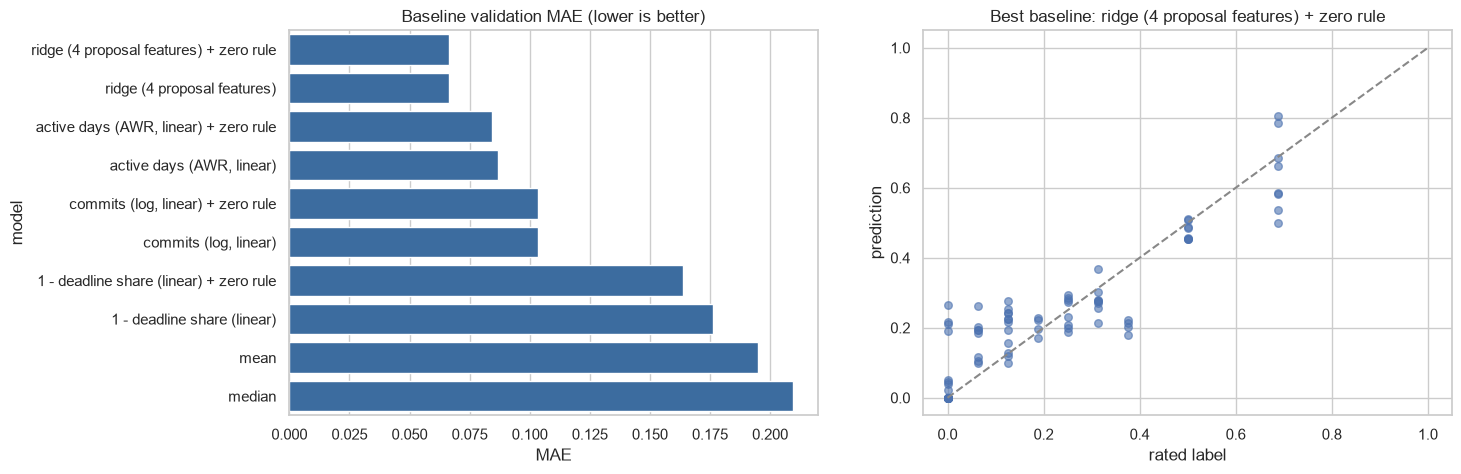

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=baselines.MAE, y=baselines.index, color="#2b6cb0", ax=axes[0])
axes[0].set(title="Baseline validation MAE (lower is better)", xlabel="MAE")
best = baselines.index[0]
g = pred[pred.model == best]
axes[1].scatter(g.y, g.pred, s=30, alpha=.6)
axes[1].plot([0, 1], [0, 1], "--", color="#888")
axes[1].set(title=f"Best baseline: {best}", xlabel="rated label", ylabel="prediction")
plt.show()

## 5. Bar to beat, and log

In [7]:
mean_mae = baselines.loc["mean"].MAE
best_mae = baselines.MAE.min()
print(f"always predicting the mean: MAE {mean_mae:.3f}")
print(f"best baseline: {baselines.index[0]} with MAE {best_mae:.3f}; a model needs MAE below {best_mae * 0.9:.3f} to be 10% better")
for model, row in baselines.iterrows():
    log_run(F, "02_splits_and_baselines", model, "validation, pooled over 20 combinations",
            {"MAE": round(row.MAE, 4), "RMSE": round(row.RMSE, 4), "pearson": round(row.Pearson, 4), "spearman": round(row.Spearman, 4),
             "bias": round(row.bias, 4), "MAE_active": round(row["MAE active only"], 4)})
print("logged to training/results/runs.csv")

always predicting the mean: MAE 0.195
best baseline: ridge (4 proposal features) + zero rule with MAE 0.066; a model needs MAE below 0.060 to be 10% better


logged to training/results/runs.csv


## 6. Reading the results

| Baseline | Validation MAE |
|---|---|
| Ridge, 4 proposal features (+ zero rule: same) | **0.066** |
| Active days alone (AWR) | 0.084-0.087 |
| Commits (log) | 0.103 |
| 1 - deadline share alone | 0.164-0.176 |
| Always predict the mean | 0.195 |

- **Unlike Effort, the proposal's features are all needed.** Ridge on the four features (0.066) clearly beats any single feature: active
  days alone is 0.087, and commit volume, the best single predictor for Effort, is only 0.103 here. Consistency is not a function of how much
  was committed.
- The deadline share alone is nearly useless (0.176, close to the mean's 0.195), matching its weak link to the label in notebook 01.
- The zero rule changes almost nothing (0.0664 vs 0.0665): the features already put inactive students at the worst values, so a linear
  model reaches 0 for them anyway.
- **The bar to beat:** a model needs MAE below about **0.060** to be 10% better than the Ridge baseline.

Leakage checks passed (no student or group in two roles; synthetic rows are train-only with both parents in training groups).

Next: **03. Preprocessing and features**.